# 7. Algoritmos meméticos

Un algoritmo memético (*memetic algorithm*) es un algoritmo genético en el que algunos individuos de cada generación pasan además por una búsqueda local. La parte genética explora el espacio de soluciones al recombinar y perturbar soluciones de la población. La búsqueda local refina a los individuos que recibe, de modo que la población se concentra pronto en soluciones que son óptimos locales o están cerca de serlo. Este capítulo presenta tres implementaciones. La primera resuelve el problema de las $n$ reinas con una representación de permutación. La segunda programa un taller de flujo de permutación, el mismo problema del capítulo 3. La tercera selecciona un portafolio de inversión con variables binarias y continuas, una restricción de cardinalidad y un operador que repara las soluciones infactibles.

## Estructura de una generación

Las tres implementaciones repiten, en cada generación, los mismos pasos:

1. selección, que escoge los individuos que se van a reproducir;
2. cruce, que combina parejas de individuos seleccionados para producir hijos;
3. mutación, que perturba a los hijos con cierta probabilidad;
4. búsqueda local, que mejora a una parte de los hijos o a todos;
5. reemplazo, en el que los hijos forman la población de la generación siguiente.

Los tres primeros pasos y el reemplazo son la parte genética. El cuarto es la parte local, y es lo que distingue a un algoritmo memético de un algoritmo genético. Las implementaciones difieren en la representación, en los operadores y en cuántos individuos reciben la búsqueda local.

In [1]:
import numpy as np
import random
import time
import itertools
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from copy import deepcopy
from scipy.optimize import minimize

## Las n reinas

### El problema y la representación

El problema consiste en ubicar $n$ reinas en un tablero de $n \times n$ de modo que ninguna ataque a otra. Cada individuo es una permutación $x = (x_0, \dots, x_{n-1})$ de los números $0, \dots, n-1$, donde $x_i$ es la fila de la reina de la columna $i$. Con esta representación hay una reina por columna y una por fila, así que solo pueden atacarse en diagonal. Dos reinas en las columnas $i$ y $j$ están en la misma diagonal cuando $|x_i - x_j| = |i - j|$, y la aptitud (*fitness*) que calcula `calcular_fitness` es el número de parejas que se atacan,

$$f(x) = \sum_{i=0}^{n-2} \sum_{j=i+1}^{n-1} \mathbb{1}\left[\,|x_i - x_j| = |i - j|\,\right].$$

El objetivo es minimizar $f$, y una solución con $f(x) = 0$ resuelve el problema.

### La parte genética

La selección es por torneo. Para cada lugar de la población, `seleccion_torneo` escoge al azar tres individuos y copia el de menor número de ataques. Los seleccionados se toman por parejas consecutivas y, con probabilidad `prob_cruce`, se cruzan con el operador PMX (*partially mapped crossover*). El PMX escoge dos puntos de corte, copia en cada hijo el segmento del otro padre y completa las demás posiciones con los valores del propio padre, siguiendo la correspondencia que define el segmento cuando un valor ya está ocupado. Así cada hijo sigue siendo una permutación. Si no hay cruce, los hijos son copias de los padres. La mutación intercambia, con probabilidad `prob_mutacion`, los valores de dos posiciones al azar.

### La parte local

Después de la mutación, el método `ejecutar` escoge al azar el 10 % de la población y le aplica `busqueda_local`. Esta búsqueda hace `intensidad_busqueda_local` intentos. En cada uno intercambia dos posiciones al azar de la mejor solución que lleva y acepta el vecino si tiene menos ataques; se detiene antes si llega a cero ataques. Los hijos reemplazan por completo a la población anterior, sin elitismo, pero la clase guarda la mejor solución encontrada en todas las generaciones. El algoritmo termina al cumplir `max_generaciones` o al encontrar una solución sin ataques.

In [2]:
class AlgoritmoMemetico:
    def __init__(self, n_reinas, tam_poblacion=100, prob_cruce=0.8, prob_mutacion=0.2,
                 max_generaciones=100, intensidad_busqueda_local=5):
        self.n_reinas = n_reinas
        self.tam_poblacion = tam_poblacion
        self.prob_cruce = prob_cruce
        self.prob_mutacion = prob_mutacion
        self.max_generaciones = max_generaciones
        self.intensidad_busqueda_local = intensidad_busqueda_local
        self.mejor_solucion = None
        self.mejor_fitness = float('inf')
        self.historial_fitness = []

    def inicializar_poblacion(self):
        """Inicializa la población con soluciones aleatorias"""
        poblacion = []
        for _ in range(self.tam_poblacion):
            # Cada individuo es una permutación de 0 a n_reinas-1
            individuo = list(range(self.n_reinas))
            random.shuffle(individuo)
            poblacion.append(individuo)
        return poblacion

    def calcular_fitness(self, individuo):
        """Calcula el número de ataques entre reinas (menor es mejor)"""
        ataques = 0
        for i in range(self.n_reinas):
            for j in range(i + 1, self.n_reinas):
                # Verificar ataques en diagonal
                if abs(individuo[i] - individuo[j]) == abs(i - j):
                    ataques += 1
        return ataques

    def seleccion_torneo(self, poblacion, tamano_torneo=3):
        """Selecciona individuos mediante torneo"""
        seleccionados = []
        for _ in range(len(poblacion)):
            participantes = random.sample(poblacion, tamano_torneo)
            ganador = min(participantes, key=self.calcular_fitness)
            seleccionados.append(ganador.copy())
        return seleccionados

    def cruce_pmx(self, padre1, padre2):
        """Cruce PMX (Partially Mapped Crossover)"""
        n = len(padre1)
        # Seleccionar puntos de corte
        punto1, punto2 = sorted(random.sample(range(n), 2))

        # Inicializar hijos con valores nulos
        hijo1 = [None] * n
        hijo2 = [None] * n

        # Copiar segmento de intercambio
        for i in range(punto1, punto2 + 1):
            hijo1[i] = padre2[i]
            hijo2[i] = padre1[i]

        # Crear mapeo
        mapeo1 = {}
        mapeo2 = {}
        for i in range(punto1, punto2 + 1):
            mapeo1[padre2[i]] = padre1[i]
            mapeo2[padre1[i]] = padre2[i]

        # Completar el resto de posiciones
        for i in range(n):
            if i < punto1 or i > punto2:
                # Para hijo1
                valor = padre1[i]
                while valor in mapeo1:
                    valor = mapeo1[valor]
                hijo1[i] = valor

                # Para hijo2
                valor = padre2[i]
                while valor in mapeo2:
                    valor = mapeo2[valor]
                hijo2[i] = valor

        return hijo1, hijo2

    def mutacion(self, individuo):
        """Mutación por intercambio de dos posiciones aleatorias"""
        if random.random() < self.prob_mutacion:
            pos1, pos2 = random.sample(range(self.n_reinas), 2)
            individuo[pos1], individuo[pos2] = individuo[pos2], individuo[pos1]
        return individuo

    def busqueda_local(self, individuo):
        """Aplica búsqueda local para mejorar un individuo"""
        mejor = individuo.copy()
        mejor_fitness = self.calcular_fitness(mejor)

        for _ in range(self.intensidad_busqueda_local):
            # Generar vecino por intercambio
            vecino = mejor.copy()
            pos1, pos2 = random.sample(range(self.n_reinas), 2)
            vecino[pos1], vecino[pos2] = vecino[pos2], vecino[pos1]

            # Evaluar vecino
            vecino_fitness = self.calcular_fitness(vecino)
            if vecino_fitness < mejor_fitness:
                mejor = vecino
                mejor_fitness = vecino_fitness

                # Si encontramos solución óptima, terminamos
                if mejor_fitness == 0:
                    break

        return mejor

    def ejecutar(self):
        """Ejecuta el algoritmo memético completo"""
        # Inicializar población
        poblacion = self.inicializar_poblacion()

        # Evolución durante varias generaciones
        for generacion in range(self.max_generaciones):
            # Evaluar población actual
            fitness_actual = [self.calcular_fitness(ind) for ind in poblacion]
            mejor_ind = poblacion[fitness_actual.index(min(fitness_actual))]
            mejor_fit = min(fitness_actual)

            # Actualizar mejor solución global
            if mejor_fit < self.mejor_fitness:
                self.mejor_fitness = mejor_fit
                self.mejor_solucion = mejor_ind.copy()

            # Guardar estadísticas
            self.historial_fitness.append(mejor_fit)

            # Verificar criterio de parada
            if self.mejor_fitness == 0:
                break

            # Selección
            seleccionados = self.seleccion_torneo(poblacion)

            # Cruce
            nueva_poblacion = []
            for i in range(0, len(seleccionados), 2):
                if i + 1 < len(seleccionados):
                    if random.random() < self.prob_cruce:
                        hijo1, hijo2 = self.cruce_pmx(seleccionados[i], seleccionados[i+1])
                    else:
                        hijo1, hijo2 = seleccionados[i].copy(), seleccionados[i+1].copy()

                    nueva_poblacion.append(hijo1)
                    nueva_poblacion.append(hijo2)
                else:
                    nueva_poblacion.append(seleccionados[i].copy())

            # Mutación
            for i in range(len(nueva_poblacion)):
                nueva_poblacion[i] = self.mutacion(nueva_poblacion[i])

            # Búsqueda local (aplicada a un subconjunto de la población)
            num_mejoras = max(1, int(self.tam_poblacion * 0.1))  # Mejorar el 10% de la población
            indices_mejora = random.sample(range(len(nueva_poblacion)), num_mejoras)

            for idx in indices_mejora:
                nueva_poblacion[idx] = self.busqueda_local(nueva_poblacion[idx])

            # Actualizar población
            poblacion = nueva_poblacion

            # Mostrar progreso
            if (generacion + 1) % 10 == 0:
                print(f"Generación {generacion + 1}: Mejor fitness = {self.mejor_fitness}")

        return self.mejor_solucion, self.mejor_fitness

Los dos métodos de presentación dibujan el tablero, con las casillas ocupadas en negro y el símbolo de la reina encima, y la evolución del menor número de ataques de cada generación.

In [3]:
def visualizar_solucion(self, solucion=None):
    """Visualiza la solución del problema de las N reinas"""
    if solucion is None:
        solucion = self.mejor_solucion

    if solucion is None:
        print("No hay solución para visualizar")
        return

    # Crear tablero
    tablero = np.zeros((self.n_reinas, self.n_reinas))
    for i, col in enumerate(solucion):
        tablero[col, i] = 1

    # Visualizar
    plt.figure(figsize=(5, 5))
    plt.imshow(tablero, cmap='binary')
    plt.title(f"Solución para {self.n_reinas} reinas (ataques: {self.mejor_fitness})")

    # Añadir cuadrícula
    plt.grid(True, color='black', linewidth=1.5)
    plt.xticks(np.arange(-0.5, self.n_reinas, 1), [])
    plt.yticks(np.arange(-0.5, self.n_reinas, 1), [])

    # Colocar reinas
    for i, col in enumerate(solucion):
        plt.text(i, col, "♛", fontsize=20, ha='center', va='center', color='white')

    plt.tight_layout()
    plt.show()

def graficar_convergencia(self):
    """Grafica la convergencia del algoritmo"""
    plt.figure(figsize=(9, 4.5))
    plt.plot(self.historial_fitness)
    plt.title("Convergencia del algoritmo memético")
    plt.xlabel("Generación")
    plt.ylabel("Aptitud (número de ataques)")
    plt.grid(True)
    plt.show()

AlgoritmoMemetico.visualizar_solucion = visualizar_solucion
AlgoritmoMemetico.graficar_convergencia = graficar_convergencia

### Ocho reinas

El primer ejemplo resuelve el tablero de $8 \times 8$ con una población de 100 individuos, probabilidad de cruce de 0,8, probabilidad de mutación de 0,2, hasta 100 generaciones y cinco intentos de búsqueda local por individuo mejorado.

Mejor solución encontrada:
[4, 2, 0, 6, 1, 7, 5, 3]
Fitness: 0
Generaciones evaluadas: 2


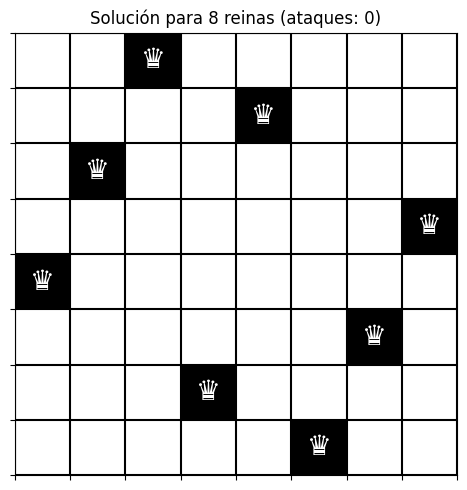

In [4]:
random.seed(42)
np.random.seed(42)

n_reinas = 8
algoritmo = AlgoritmoMemetico(n_reinas,
                              tam_poblacion=100,
                              prob_cruce=0.8,
                              prob_mutacion=0.2,
                              max_generaciones=100,
                              intensidad_busqueda_local=5)

mejor_solucion, mejor_fitness = algoritmo.ejecutar()

print("Mejor solución encontrada:")
print(mejor_solucion)
print(f"Fitness: {mejor_fitness}")
print(f"Generaciones evaluadas: {len(algoritmo.historial_fitness)}")

# Visualizar solución
algoritmo.visualizar_solucion()

Con ocho reinas el algoritmo encuentra una solución sin ataques en la segunda generación que evalúa, es decir, después de una sola ronda de selección, cruce, mutación y búsqueda local. El tablero muestra una reina por fila y por columna, como garantiza la representación, y ninguna pareja de reinas comparte una diagonal.

### Ochenta reinas

Con $n = 80$ el número de parejas de reinas que hay que revisar en cada evaluación pasa de 28 a 3160, de modo que cada evaluación cuesta más de cien veces lo que costaba con ocho reinas. Se usan los mismos parámetros que en el ejemplo anterior.

Generación 10: Mejor fitness = 29


Generación 20: Mejor fitness = 23


Generación 30: Mejor fitness = 17


Generación 40: Mejor fitness = 11


Generación 50: Mejor fitness = 8


Generación 60: Mejor fitness = 4


Generación 70: Mejor fitness = 3


Generación 80: Mejor fitness = 2


Generación 90: Mejor fitness = 2


Generación 100: Mejor fitness = 1

Fitness: 1
Tiempo de ejecución: 9.4 segundos


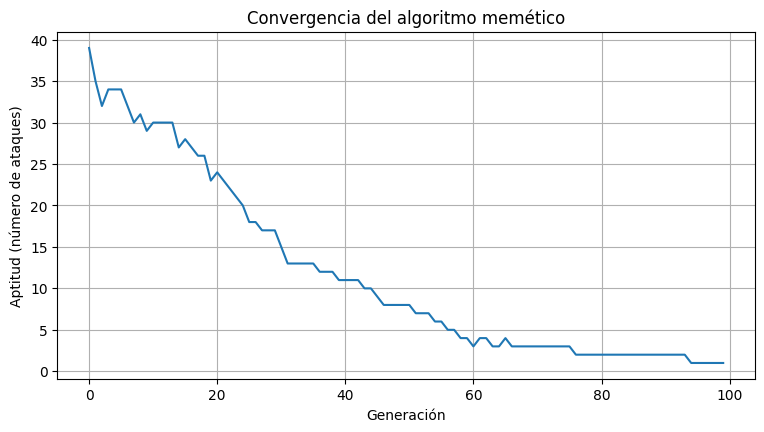

In [5]:
random.seed(42)
np.random.seed(42)

n_reinas = 80
algoritmo = AlgoritmoMemetico(n_reinas,
                              tam_poblacion=100,
                              prob_cruce=0.8,
                              prob_mutacion=0.2,
                              max_generaciones=100,
                              intensidad_busqueda_local=5)

inicio = time.time()
mejor_solucion, mejor_fitness = algoritmo.ejecutar()
fin = time.time()

print(f"\nFitness: {mejor_fitness}")
print(f"Tiempo de ejecución: {fin - inicio:.1f} segundos")

# Mostrar gráfica de convergencia
algoritmo.graficar_convergencia()

Con 80 reinas, el número de ataques del mejor individuo de cada generación baja de manera sostenida, pero al cabo de las 100 generaciones queda un ataque. La curva sube en algunas generaciones porque la nueva población reemplaza por completo a la anterior y el mejor individuo se puede perder. La clase conserva de todos modos la mejor solución encontrada, que es la que devuelve `ejecutar`.

## Taller de flujo de permutación

### El problema y la representación

El problema del taller de flujo de permutación se presentó en el capítulo 3. Aunque la documentación de la clase siguiente habla de *job shop*, el problema que resuelve es ese taller de flujo, porque todos los trabajos pasan por las máquinas en el mismo orden y una solución es una sola permutación de los trabajos, que se aplica a todas las máquinas. El método `calcular_makespan` implementa la misma recurrencia del capítulo 3,

$$C_{j,m} = \max\left(C_{j,m-1},\, C_{j-1,m}\right) + p_{\pi_j,m},$$

con la diferencia de que guarda los tiempos de terminación indexados por el número del trabajo y no por su posición en la secuencia.

### La parte genética

En esta implementación no hay un operador de selección. Mientras la nueva población no esté completa, el método `ejecutar` decide con probabilidad `prob_cruce` si cruza. Si cruza, escoge dos padres al azar, con la misma probabilidad para todos, y agrega los dos hijos del cruce PMX. Si no cruza, agrega un individuo de la población escogido al azar. Al final recorta la nueva población al tamaño `tam_poblacion`. El PMX de esta clase copia en cada hijo el segmento de su propio padre entre los dos puntos de corte, ubica los valores del segmento del otro padre siguiendo la correspondencia y llena las posiciones restantes con el otro padre. La mutación intercambia dos posiciones al azar con probabilidad `prob_mutacion`.

### La parte local

Todos los individuos de la nueva población pasan por `busqueda_local`, que hace `max_busqueda_local` intentos. En cada intento intercambia dos trabajos adyacentes, en una posición escogida al azar, y acepta el cambio si baja el tiempo total de terminación. Como en las reinas, no hay elitismo y la clase guarda la mejor solución de todas las generaciones.

In [6]:
class AlgoritmoMemetico:
    """
    Implementación de un Algoritmo Memético para resolver el problema de secuenciación de trabajos en máquinas (Job Shop Scheduling).

    El algoritmo combina conceptos de algoritmos genéticos con búsqueda local para encontrar una secuencia óptima de trabajos
    que minimice el tiempo total de completación (makespan).

    Atributos:
        num_trabajos (int): Número de trabajos a programar
        num_maquinas (int): Número de máquinas disponibles
        tiempos_procesamiento (list): Matriz con los tiempos de procesamiento de cada trabajo en cada máquina
        tam_poblacion (int): Tamaño de la población de soluciones
        prob_cruce (float): Probabilidad de cruce entre soluciones (0-1)
        prob_mutacion (float): Probabilidad de mutación de una solución (0-1)
        max_generaciones (int): Número máximo de generaciones a ejecutar
        max_busqueda_local (int): Número máximo de iteraciones en la búsqueda local
    """

    def __init__(self, num_trabajos, num_maquinas, tiempos_procesamiento,
                 tam_poblacion=50, prob_cruce=0.8, prob_mutacion=0.1,
                 max_generaciones=100, max_busqueda_local=20):
        self.num_trabajos = num_trabajos
        self.num_maquinas = num_maquinas
        self.tiempos_procesamiento = tiempos_procesamiento
        self.tam_poblacion = tam_poblacion
        self.prob_cruce = prob_cruce
        self.prob_mutacion = prob_mutacion
        self.max_generaciones = max_generaciones
        self.max_busqueda_local = max_busqueda_local

    def generar_solucion_inicial(self):
        """
        Genera una solución inicial aleatoria.

        Returns:
            list: Una permutación aleatoria de los trabajos
        """
        solucion = list(range(self.num_trabajos))
        random.shuffle(solucion)
        return solucion

    def calcular_makespan(self, solucion):
        """
        Calcula el tiempo total de completación (makespan) para una secuencia dada.

        Args:
            solucion (list): Secuencia de trabajos a evaluar

        Returns:
            float: Tiempo total de completación de todos los trabajos
        """
        tiempos_fin = [[0 for _ in range(self.num_maquinas)] for _ in range(self.num_trabajos)]

        for i, trabajo in enumerate(solucion):
            for j in range(self.num_maquinas):
                if i == 0 and j == 0:
                    tiempos_fin[trabajo][j] = self.tiempos_procesamiento[trabajo][j]
                elif i == 0:
                    tiempos_fin[trabajo][j] = (tiempos_fin[trabajo][j-1] +
                                             self.tiempos_procesamiento[trabajo][j])
                elif j == 0:
                    tiempos_fin[trabajo][j] = (tiempos_fin[solucion[i-1]][j] +
                                             self.tiempos_procesamiento[trabajo][j])
                else:
                    tiempos_fin[trabajo][j] = max(tiempos_fin[trabajo][j-1],
                                                tiempos_fin[solucion[i-1]][j]) + \
                                            self.tiempos_procesamiento[trabajo][j]

        return tiempos_fin[solucion[-1]][self.num_maquinas-1]

    def cruce_pmx(self, padre1, padre2):
        """
        Realiza el cruce PMX (Partially Mapped Crossover) entre dos soluciones padre.

        Args:
            padre1 (list): Primera solución padre
            padre2 (list): Segunda solución padre

        Returns:
            tuple: Par de soluciones hijo generadas
        """
        n = len(padre1)
        punto1, punto2 = sorted(random.sample(range(n), 2))

        hijo1 = [-1] * n
        hijo2 = [-1] * n

        # Copiar segmento del punto1 al punto2
        hijo1[punto1:punto2] = padre1[punto1:punto2]
        hijo2[punto1:punto2] = padre2[punto1:punto2]

        # Mapeo para el resto de posiciones
        for i in range(punto1, punto2):
            if padre2[i] not in hijo1:
                pos = padre2.index(padre1[i])
                while hijo1[pos] != -1:
                    pos = padre2.index(padre1[pos])
                hijo1[pos] = padre2[i]

            if padre1[i] not in hijo2:
                pos = padre1.index(padre2[i])
                while hijo2[pos] != -1:
                    pos = padre1.index(padre2[pos])
                hijo2[pos] = padre1[i]

        # Rellenar posiciones restantes
        for i in range(n):
            if hijo1[i] == -1:
                hijo1[i] = padre2[i]
            if hijo2[i] == -1:
                hijo2[i] = padre1[i]

        return hijo1, hijo2

    def mutacion(self, solucion):
        """
        Aplica operador de mutación por intercambio a una solución.

        Args:
            solucion (list): Solución a mutar

        Returns:
            list: Solución mutada
        """
        if random.random() < self.prob_mutacion:
            i, j = random.sample(range(len(solucion)), 2)
            solucion[i], solucion[j] = solucion[j], solucion[i]
        return solucion

    def busqueda_local(self, solucion):
        """
        Aplica búsqueda local mediante intercambio de pares adyacentes.

        Args:
            solucion (list): Solución inicial para la búsqueda local

        Returns:
            list: Mejor solución encontrada en el vecindario
        """
        mejor_solucion = deepcopy(solucion)
        mejor_makespan = self.calcular_makespan(mejor_solucion)

        for _ in range(self.max_busqueda_local):
            i = random.randint(0, len(solucion)-2)
            nueva_solucion = deepcopy(mejor_solucion)
            nueva_solucion[i], nueva_solucion[i+1] = nueva_solucion[i+1], nueva_solucion[i]

            nuevo_makespan = self.calcular_makespan(nueva_solucion)
            if nuevo_makespan < mejor_makespan:
                mejor_solucion = nueva_solucion
                mejor_makespan = nuevo_makespan

        return mejor_solucion

    def ejecutar(self):
        """
        Ejecuta el algoritmo memético completo.

        Returns:
            tuple: (mejor_solucion, mejor_makespan) - La mejor secuencia encontrada y su makespan
        """
        # Generar población inicial
        poblacion = [self.generar_solucion_inicial() for _ in range(self.tam_poblacion)]
        mejor_global = min(poblacion, key=self.calcular_makespan)
        mejor_makespan_global = self.calcular_makespan(mejor_global)

        for generacion in range(self.max_generaciones):
            nueva_poblacion = []

            # Selección y reproducción
            while len(nueva_poblacion) < self.tam_poblacion:
                if random.random() < self.prob_cruce:
                    padres = random.sample(poblacion, 2)
                    hijo1, hijo2 = self.cruce_pmx(padres[0], padres[1])
                    nueva_poblacion.extend([hijo1, hijo2])
                else:
                    nueva_poblacion.append(random.choice(poblacion))

            # Ajustar tamaño de población
            nueva_poblacion = nueva_poblacion[:self.tam_poblacion]

            # Mutación y búsqueda local
            for i in range(len(nueva_poblacion)):
                nueva_poblacion[i] = self.mutacion(nueva_poblacion[i])
                nueva_poblacion[i] = self.busqueda_local(nueva_poblacion[i])

            # Actualizar población
            poblacion = nueva_poblacion

            # Actualizar mejor solución global
            mejor_actual = min(poblacion, key=self.calcular_makespan)
            makespan_actual = self.calcular_makespan(mejor_actual)
            if makespan_actual < mejor_makespan_global:
                mejor_global = mejor_actual
                mejor_makespan_global = makespan_actual

            if (generacion + 1) % 10 == 0:
                print(f"Generación {generacion + 1}: Mejor makespan = {mejor_makespan_global}")

        return mejor_global, mejor_makespan_global

    def calcular_tiempos_inicio_fin(self, solucion):
        """
        Calcula los tiempos de inicio y fin de cada trabajo en cada máquina.

        Args:
            solucion (list): Secuencia de trabajos a evaluar

        Returns:
            tuple: (tiempos_inicio, tiempos_fin) - Matrices con los tiempos de inicio y fin
        """
        tiempos_inicio = [[0 for _ in range(self.num_maquinas)] for _ in range(self.num_trabajos)]
        tiempos_fin = [[0 for _ in range(self.num_maquinas)] for _ in range(self.num_trabajos)]

        for i, trabajo in enumerate(solucion):
            for j in range(self.num_maquinas):
                if i == 0 and j == 0:
                    tiempos_inicio[trabajo][j] = 0
                    tiempos_fin[trabajo][j] = self.tiempos_procesamiento[trabajo][j]
                elif i == 0:
                    tiempos_inicio[trabajo][j] = tiempos_fin[trabajo][j-1]
                    tiempos_fin[trabajo][j] = tiempos_inicio[trabajo][j] + self.tiempos_procesamiento[trabajo][j]
                elif j == 0:
                    tiempos_inicio[trabajo][j] = tiempos_fin[solucion[i-1]][j]
                    tiempos_fin[trabajo][j] = tiempos_inicio[trabajo][j] + self.tiempos_procesamiento[trabajo][j]
                else:
                    tiempos_inicio[trabajo][j] = max(tiempos_fin[trabajo][j-1], tiempos_fin[solucion[i-1]][j])
                    tiempos_fin[trabajo][j] = tiempos_inicio[trabajo][j] + self.tiempos_procesamiento[trabajo][j]

        return tiempos_inicio, tiempos_fin

El diagrama de Gantt de esta clase usa los tiempos de inicio de `calcular_tiempos_inicio_fin`. Cada fila es una máquina, cada rectángulo es un trabajo y la línea roja punteada marca el tiempo total de terminación.

In [7]:
def visualizar_solucion(self, solucion):
    """
    Visualiza la solución como un diagrama de Gantt.

    Args:
        solucion (list): Secuencia de trabajos a visualizar
    """
    tiempos_inicio, tiempos_fin = self.calcular_tiempos_inicio_fin(solucion)
    makespan = self.calcular_makespan(solucion)

    # Crear figura y ejes
    fig, ax = plt.subplots(figsize=(11, 5))

    # Colores para los trabajos
    colores = plt.cm.tab10.colors

    # Dibujar las tareas en el diagrama de Gantt
    for maquina in range(self.num_maquinas):
        for i, trabajo in enumerate(solucion):
            inicio = tiempos_inicio[trabajo][maquina]
            duracion = self.tiempos_procesamiento[trabajo][maquina]

            # Crear rectángulo para la tarea
            rect = patches.Rectangle(
                (inicio, maquina), duracion, 0.8,
                linewidth=1, edgecolor='black',
                facecolor=colores[trabajo % len(colores)],
                alpha=0.7
            )
            ax.add_patch(rect)

            # Añadir etiqueta con el número de trabajo
            ax.text(
                inicio + duracion/2, maquina + 0.4,
                f'T{trabajo}',
                ha='center', va='center',
                fontsize=10, fontweight='bold'
            )

    # Configurar ejes
    ax.set_ylim(-0.2, self.num_maquinas + 0.2)
    ax.set_xlim(0, makespan * 1.05)
    ax.set_yticks([m + 0.4 for m in range(self.num_maquinas)])
    ax.set_yticklabels([f'Máquina {i+1}' for i in range(self.num_maquinas)])
    ax.set_xlabel('Tiempo')
    ax.set_title('Diagrama de Gantt - Secuenciación de Trabajos')

    # Añadir leyenda
    legend_elements = [
        patches.Patch(facecolor=colores[i % len(colores)], edgecolor='black', alpha=0.7, label=f'Trabajo {i}')
        for i in range(self.num_trabajos)
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.01, 1),
              ncol=2 if self.num_trabajos > 10 else 1)

    # Añadir línea vertical para el makespan
    ax.axvline(x=makespan, color='red', linestyle='--', linewidth=2)
    ax.text(makespan + 0.1, -0.1, f'Makespan: {makespan}', color='red', fontweight='bold')

    plt.tight_layout()
    plt.show()

AlgoritmoMemetico.visualizar_solucion = visualizar_solucion

### Ejemplo con 3 trabajos y 3 máquinas

El ejemplo del curso tiene tres trabajos y tres máquinas, con los parámetros por omisión de la clase: población de 50 individuos, probabilidad de cruce de 0,8, probabilidad de mutación de 0,1, 100 generaciones y 20 intentos de búsqueda local por individuo.

Generación 10: Mejor makespan = 12
Generación 20: Mejor makespan = 12
Generación 30: Mejor makespan = 12


Generación 40: Mejor makespan = 12
Generación 50: Mejor makespan = 12


Generación 60: Mejor makespan = 12
Generación 70: Mejor makespan = 12
Generación 80: Mejor makespan = 12


Generación 90: Mejor makespan = 12
Generación 100: Mejor makespan = 12

Mejor solución encontrada: [1, 0, 2]
Makespan: 12


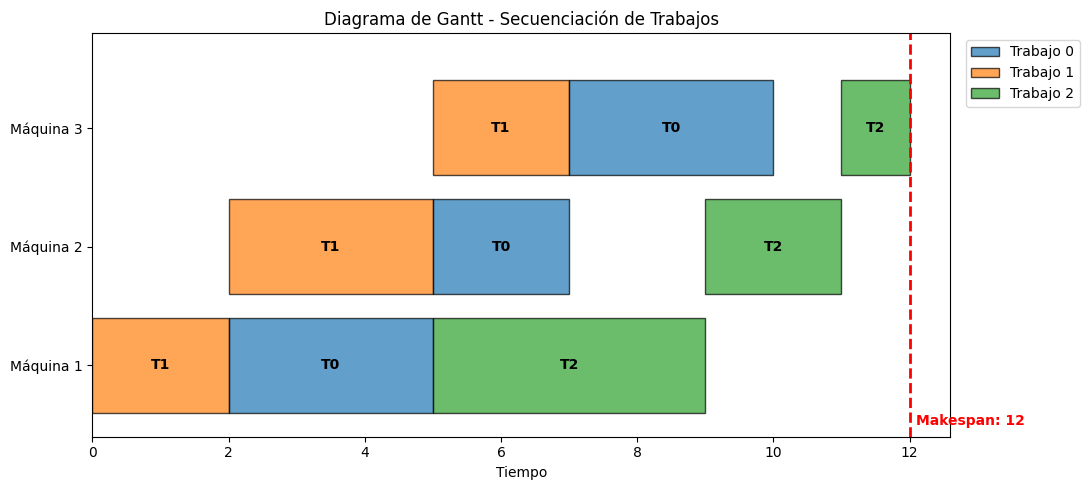

In [8]:
random.seed(42)
np.random.seed(42)

# Ejemplo con un problema pequeño de 3 trabajos y 3 máquinas
num_trabajos = 3
num_maquinas = 3
tiempos_procesamiento = [
    [3, 2, 3],  # Trabajo 0
    [2, 3, 2],  # Trabajo 1
    [4, 2, 1]   # Trabajo 2
]

algoritmo = AlgoritmoMemetico(num_trabajos, num_maquinas, tiempos_procesamiento)
mejor_solucion, mejor_makespan = algoritmo.ejecutar()

print("\nMejor solución encontrada:", mejor_solucion)
print("Makespan:", mejor_makespan)

# Visualizar la solución como diagrama de Gantt
algoritmo.visualizar_solucion(mejor_solucion)

Con tres trabajos solo hay $3! = 6$ secuencias posibles, así que el resultado se puede comparar con una enumeración completa.

In [9]:
for secuencia in itertools.permutations(range(num_trabajos)):
    print(list(secuencia), algoritmo.calcular_makespan(list(secuencia)))

[0, 1, 2] 12
[0, 2, 1] 14
[1, 0, 2] 12
[1, 2, 0] 14
[2, 0, 1] 14
[2, 1, 0] 14


Al cabo de las primeras diez generaciones el algoritmo ya tiene la secuencia [1, 0, 2], con tiempo total de terminación 12. La enumeración muestra que 12 es el menor valor posible y que lo alcanzan dos secuencias, [0, 1, 2] y [1, 0, 2]. En el diagrama, la máquina 1 trabaja sin interrupciones, mientras que las máquinas 2 y 3 quedan ociosas un tiempo antes de recibir el trabajo 2, que es el último de la secuencia.

### La instancia de 20 trabajos y 5 máquinas del capítulo 3

Para ver el algoritmo en una instancia en la que la enumeración ya no es posible, se usa la misma instancia del capítulo 3, generada con la misma semilla, y los mismos parámetros del ejemplo anterior.

Generación 10: Mejor makespan = 1349


Generación 20: Mejor makespan = 1314


Generación 30: Mejor makespan = 1314


Generación 40: Mejor makespan = 1314


Generación 50: Mejor makespan = 1314


Generación 60: Mejor makespan = 1314


Generación 70: Mejor makespan = 1314


Generación 80: Mejor makespan = 1314


Generación 90: Mejor makespan = 1314


Generación 100: Mejor makespan = 1314

Mejor solución encontrada: [14, 7, 4, 15, 11, 13, 12, 8, 19, 6, 5, 10, 17, 9, 0, 2, 18, 1, 16, 3]
Makespan: 1314
Tiempo de ejecución: 3.1 segundos


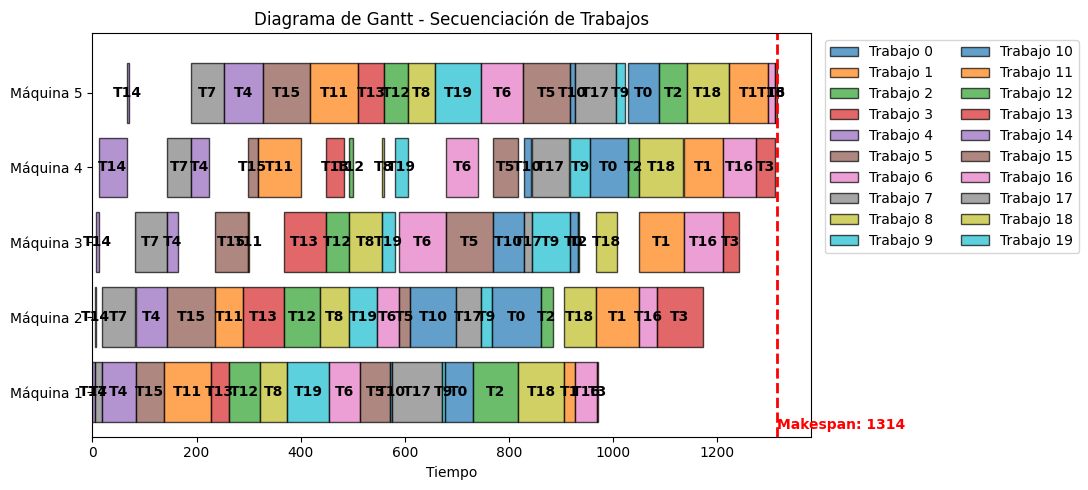

In [10]:
np.random.seed(42)
tiempos_procesamiento = np.random.randint(1, 100, size=(20, 5)).tolist()
random.seed(42)

algoritmo = AlgoritmoMemetico(20, 5, tiempos_procesamiento)
inicio = time.time()
mejor_solucion, mejor_makespan = algoritmo.ejecutar()
fin = time.time()

print("\nMejor solución encontrada:", mejor_solucion)
print("Makespan:", mejor_makespan)
print(f"Tiempo de ejecución: {fin - inicio:.1f} segundos")

algoritmo.visualizar_solucion(mejor_solucion)

En la instancia del capítulo 3, el tiempo total de terminación baja en las primeras 20 generaciones y queda en 1314 hasta el final. En la misma instancia, la búsqueda en vecindarios grandes del capítulo 3 llegó a 1308. Una corrida de cada método no basta para decir cuál es mejor, porque los dos dependen de la semilla; el capítulo 10 trata cómo hacer esa comparación.

## Selección de portafolio

### El problema

Hay $N$ activos, con retornos esperados $\mu_i$ y matriz de covarianza $\Sigma$. Una solución tiene dos partes, una variable binaria $z_i$ que indica si el activo $i$ entra al portafolio y una proporción continua $w_i$ del capital invertida en él. Por eso el problema es de variables mixtas. Las restricciones que la clase documenta son las siguientes:

$$\sum_{i=1}^{N} w_i = 1, \qquad \sum_{i=1}^{N} z_i \le K, \qquad w_{\min}\, z_i \le w_i \le w_{\max}\, z_i, \qquad \sum_{i \in S} w_i \le s_{\max} \ \text{para cada sector } S.$$

La segunda es la restricción de cardinalidad, con $K$ igual a `max_activos`. La aptitud que calcula `calcular_fitness` pondera el retorno y la varianza del portafolio con el parámetro $\lambda$ (`lambda_riesgo`),

$$f(w) = (1-\lambda)\, \mu^\top w - \lambda\, w^\top \Sigma w,$$

y el algoritmo la maximiza.

### Representación y reparación

Cada individuo es un diccionario con dos vectores de longitud $N$, `seleccion` (los $z_i$) y `proporciones` (los $w_i$). Los operadores genéticos pueden producir individuos que incumplen las restricciones, y el método `reparar_solucion` los corrige con estos pasos, en este orden:

1. si no hay activos seleccionados, selecciona uno al azar;
2. si hay más de $K$ activos seleccionados, quita al azar los que sobran;
3. anula la proporción de los activos no seleccionados y normaliza las proporciones para que sumen 1, o reparte el capital en partes iguales si todas son cero;
4. para cada activo con $w_i < w_{\min}$, lo retira del portafolio si $w_{\min}$ por el número de activos seleccionados supera 1 y, si no, sube su proporción a $w_{\min}$;
5. baja a $w_{\max}$ las proporciones que lo superan y normaliza otra vez;
6. para cada sector cuya exposición supera $s_{\max}$, multiplica las proporciones de sus activos por $s_{\max}$ dividido por la exposición, y normaliza al final.

Las normalizaciones de los pasos 5 y 6 pueden sacar de nuevo alguna proporción de sus límites, de modo que la reparación acerca el individuo a la región factible pero no garantiza que la alcance. Un portafolio de un solo activo, por ejemplo, queda con $w_i = 1$ aunque $w_{\max}$ sea menor. Por eso, al final del ejemplo se revisan las restricciones de la mejor solución.

### La parte genética

La selección es por torneo de tres individuos, esta vez con el de mayor aptitud como ganador. El cruce, con probabilidad `prob_cruce`, trata cada parte con un operador distinto. Para la selección de activos usa un cruce uniforme, en el que una máscara aleatoria decide de qué padre hereda cada hijo cada $z_i$. Para las proporciones usa un cruce aritmético con $\alpha \sim U(0,1)$,

$$w^{(1)} = \alpha\, w^{(A)} + (1-\alpha)\, w^{(B)}, \qquad w^{(2)} = (1-\alpha)\, w^{(A)} + \alpha\, w^{(B)},$$

y repara a los dos hijos. La mutación se aplica a un individuo con probabilidad `prob_mutacion`. Cuando ocurre, invierte cada $z_i$ con probabilidad 0,1, multiplica la proporción del 20 % de los activos seleccionados por un factor aleatorio entre 0,8 y 1,2, y repara el resultado.

### La parte local

La búsqueda local fija la selección de activos y optimiza las proporciones de los activos seleccionados con el método SLSQP de `scipy.optimize.minimize`. Minimiza $-f(w)$ sujeto a $\sum_i w_i = 1$ y a los límites $w_{\min} \le w_i \le w_{\max}$, con un máximo de 100 iteraciones, y repara el resultado. La restricción de sectores no entra en este subproblema y queda a cargo de la reparación. El esfuerzo de la búsqueda lo fija ese máximo de iteraciones, ya que el parámetro `intensidad_busqueda_local` se recibe pero el método no lo usa. En cada generación la búsqueda local se aplica al 10 % de la población, escogido al azar, y al terminar se aplica una vez más a la mejor solución. A diferencia de los dos ejemplos anteriores, hay elitismo, porque el mejor individuo de la generación anterior reemplaza al primero de la nueva población.

In [11]:
class AlgoritmoMemeticoPortafolio:
    """
    Algoritmo Memético para el Problema de Selección de Portafolio

    Este algoritmo resuelve el problema de selección de portafolio con variables mixtas
    (enteras y continuas) donde:

    - Variables enteras: Decisión de incluir o no un activo (0 o 1)
    - Variables continuas: Proporción de inversión en cada activo seleccionado

    Restricciones:
    1. La suma de las proporciones debe ser igual a 1 (todo el capital se invierte)
    2. Número máximo de activos en el portafolio (cardinalidad)
    3. Límites mínimos y máximos de inversión para cada activo (si se selecciona)
    4. Restricciones de sector (límites en la exposición a ciertos sectores)

    Función objetivo:
    - Maximizar el retorno esperado
    - Minimizar el riesgo (varianza del portafolio)
    - Balancear ambos objetivos mediante un parámetro lambda
    """

    def __init__(self, retornos_esperados, matriz_covarianza, tam_poblacion=50,
                 prob_cruce=0.8, prob_mutacion=0.2, max_generaciones=100,
                 intensidad_busqueda_local=5, lambda_riesgo=0.5, max_activos=10,
                 min_proporcion=0.01, max_proporcion=0.5, sectores=None, max_sector=0.4):
        """
        Inicializa el algoritmo memético para selección de portafolio.

        Args:
            retornos_esperados: Vector de retornos esperados para cada activo
            matriz_covarianza: Matriz de covarianza entre los activos
            tam_poblacion: Tamaño de la población
            prob_cruce: Probabilidad de cruce
            prob_mutacion: Probabilidad de mutación
            max_generaciones: Número máximo de generaciones
            intensidad_busqueda_local: Intensidad de la búsqueda local
            lambda_riesgo: Ponderación entre retorno (1-lambda) y riesgo (lambda)
            max_activos: Número máximo de activos en el portafolio
            min_proporcion: Proporción mínima para cada activo seleccionado
            max_proporcion: Proporción máxima para cada activo seleccionado
            sectores: Lista que indica el sector de cada activo (opcional)
            max_sector: Exposición máxima a un sector (opcional)
        """
        self.retornos = np.array(retornos_esperados)
        self.covarianza = np.array(matriz_covarianza)
        self.n_activos = len(retornos_esperados)
        self.tam_poblacion = tam_poblacion
        self.prob_cruce = prob_cruce
        self.prob_mutacion = prob_mutacion
        self.max_generaciones = max_generaciones
        self.intensidad_busqueda_local = intensidad_busqueda_local
        self.lambda_riesgo = lambda_riesgo
        self.max_activos = min(max_activos, self.n_activos)
        self.min_proporcion = min_proporcion
        self.max_proporcion = max_proporcion
        self.sectores = sectores
        self.max_sector = max_sector

        self.mejor_solucion = None
        self.mejor_fitness = float('-inf')  # Maximizamos, así que empezamos con -infinito
        self.historial_fitness = []

    def inicializar_poblacion(self):
        """Inicializa la población con soluciones aleatorias válidas"""
        poblacion = []
        for _ in range(self.tam_poblacion):
            # Generar selección de activos (parte entera)
            num_activos = random.randint(1, self.max_activos)
            seleccion = np.zeros(self.n_activos, dtype=int)
            indices_seleccionados = random.sample(range(self.n_activos), num_activos)
            seleccion[indices_seleccionados] = 1

            # Generar proporciones (parte continua)
            proporciones = np.zeros(self.n_activos)
            pesos_iniciales = np.random.random(num_activos)
            pesos_iniciales = pesos_iniciales / np.sum(pesos_iniciales)  # Normalizar

            for i, idx in enumerate(indices_seleccionados):
                proporciones[idx] = pesos_iniciales[i]

            # Crear individuo (selección + proporciones)
            individuo = {
                'seleccion': seleccion,
                'proporciones': proporciones
            }

            # Reparar si es necesario
            individuo = self.reparar_solucion(individuo)
            poblacion.append(individuo)

        return poblacion

    def reparar_solucion(self, individuo):
        """Repara una solución para que cumpla todas las restricciones"""
        seleccion = individuo['seleccion']
        proporciones = individuo['proporciones'].copy()

        # Asegurar que hay al menos un activo seleccionado
        if np.sum(seleccion) == 0:
            idx = random.randint(0, self.n_activos - 1)
            seleccion[idx] = 1

        # Asegurar que no hay más del máximo de activos
        if np.sum(seleccion) > self.max_activos:
            indices_seleccionados = np.where(seleccion == 1)[0]
            indices_a_eliminar = random.sample(list(indices_seleccionados),
                                              int(np.sum(seleccion) - self.max_activos))
            seleccion[indices_a_eliminar] = 0
            proporciones[indices_a_eliminar] = 0

        # Asegurar que solo los activos seleccionados tienen proporción
        proporciones = proporciones * seleccion

        # Normalizar proporciones para que sumen 1
        if np.sum(proporciones) > 0:
            proporciones = proporciones / np.sum(proporciones)
        else:
            # Si todas las proporciones son 0, asignar uniformemente
            indices_seleccionados = np.where(seleccion == 1)[0]
            for idx in indices_seleccionados:
                proporciones[idx] = 1.0 / len(indices_seleccionados)

        # Aplicar restricciones de proporción mínima y máxima
        indices_seleccionados = np.where(seleccion == 1)[0]

        # Verificar restricciones de proporción mínima
        for idx in indices_seleccionados:
            if proporciones[idx] < self.min_proporcion:
                # Si no se puede cumplir la restricción, eliminar el activo
                if len(indices_seleccionados) > 1 and self.min_proporcion * len(indices_seleccionados) > 1:
                    seleccion[idx] = 0
                    proporciones[idx] = 0
                else:
                    proporciones[idx] = self.min_proporcion

        # Verificar restricciones de proporción máxima
        for idx in indices_seleccionados:
            if proporciones[idx] > self.max_proporcion:
                proporciones[idx] = self.max_proporcion

        # Normalizar de nuevo después de ajustes
        if np.sum(proporciones) > 0:
            proporciones = proporciones / np.sum(proporciones)

        # Verificar restricciones de sector si aplican
        if self.sectores is not None:
            # Calcular exposición por sector
            unique_sectors = set(self.sectores)
            for sector in unique_sectors:
                sector_indices = [i for i, s in enumerate(self.sectores) if s == sector]
                sector_exposure = sum(proporciones[i] for i in sector_indices)

                # Si excede el máximo, reducir proporcionalmente
                if sector_exposure > self.max_sector:
                    reduction_factor = self.max_sector / sector_exposure
                    for idx in sector_indices:
                        if seleccion[idx] == 1:
                            proporciones[idx] *= reduction_factor

            # Normalizar de nuevo después de ajustes de sector
            if np.sum(proporciones) > 0:
                proporciones = proporciones / np.sum(proporciones)

        return {
            'seleccion': seleccion,
            'proporciones': proporciones
        }

    def calcular_fitness(self, individuo):
        """
        Calcula el fitness de un individuo (mayor es mejor)
        Combina retorno esperado y riesgo según lambda_riesgo
        """
        proporciones = individuo['proporciones']

        # Calcular retorno esperado del portafolio
        retorno_portafolio = np.sum(proporciones * self.retornos)

        # Calcular riesgo (varianza) del portafolio
        riesgo_portafolio = proporciones.T @ self.covarianza @ proporciones

        # Función objetivo: maximizar retorno y minimizar riesgo
        # Nota: Negamos el riesgo porque queremos maximizar el fitness
        fitness = (1 - self.lambda_riesgo) * retorno_portafolio - self.lambda_riesgo * riesgo_portafolio

        return fitness

    def seleccion_torneo(self, poblacion, tamano_torneo=3):
        """Selecciona individuos mediante torneo"""
        seleccionados = []
        for _ in range(len(poblacion)):
            participantes = random.sample(poblacion, tamano_torneo)
            ganador = max(participantes, key=self.calcular_fitness)
            seleccionados.append(self.copiar_individuo(ganador))
        return seleccionados

    def copiar_individuo(self, individuo):
        """Crea una copia profunda de un individuo"""
        return {
            'seleccion': individuo['seleccion'].copy(),
            'proporciones': individuo['proporciones'].copy()
        }

    def cruce(self, padre1, padre2):
        """
        Realiza el cruce entre dos individuos:
        - Para la parte entera (selección): cruce uniforme
        - Para la parte continua (proporciones): cruce aritmético
        """
        if random.random() >= self.prob_cruce:
            return self.copiar_individuo(padre1), self.copiar_individuo(padre2)

        # Cruce de la parte entera (selección)
        mascara = np.random.randint(0, 2, self.n_activos)
        seleccion_hijo1 = np.where(mascara, padre1['seleccion'], padre2['seleccion'])
        seleccion_hijo2 = np.where(mascara, padre2['seleccion'], padre1['seleccion'])

        # Cruce de la parte continua (proporciones)
        alpha = random.random()  # Factor de mezcla
        proporciones_hijo1 = alpha * padre1['proporciones'] + (1 - alpha) * padre2['proporciones']
        proporciones_hijo2 = (1 - alpha) * padre1['proporciones'] + alpha * padre2['proporciones']

        # Crear hijos
        hijo1 = {'seleccion': seleccion_hijo1, 'proporciones': proporciones_hijo1}
        hijo2 = {'seleccion': seleccion_hijo2, 'proporciones': proporciones_hijo2}

        # Reparar soluciones
        hijo1 = self.reparar_solucion(hijo1)
        hijo2 = self.reparar_solucion(hijo2)

        return hijo1, hijo2

    def mutacion(self, individuo):
        """
        Aplica mutación a un individuo:
        - Para la parte entera: cambiar estado de selección de algunos activos
        - Para la parte continua: ajustar proporciones
        """
        if random.random() >= self.prob_mutacion:
            return individuo

        seleccion = individuo['seleccion'].copy()
        proporciones = individuo['proporciones'].copy()

        # Mutación de la parte entera (selección)
        for i in range(self.n_activos):
            if random.random() < 0.1:  # 10% de probabilidad de mutar cada gen
                seleccion[i] = 1 - seleccion[i]  # Invertir 0->1 o 1->0

        # Mutación de la parte continua (proporciones)
        indices_seleccionados = np.where(seleccion == 1)[0]
        if len(indices_seleccionados) > 0:
            # Seleccionar algunos activos para ajustar sus proporciones
            num_a_mutar = max(1, int(len(indices_seleccionados) * 0.2))
            indices_a_mutar = random.sample(list(indices_seleccionados), num_a_mutar)

            for idx in indices_a_mutar:
                # Ajustar proporción con un factor aleatorio entre 0.8 y 1.2
                factor = 0.8 + 0.4 * random.random()
                proporciones[idx] *= factor

        # Crear individuo mutado
        individuo_mutado = {'seleccion': seleccion, 'proporciones': proporciones}

        # Reparar solución
        return self.reparar_solucion(individuo_mutado)

    def busqueda_local(self, individuo):
        """
        Aplica búsqueda local para mejorar un individuo:
        - Optimiza las proporciones manteniendo fija la selección de activos
        """
        seleccion = individuo['seleccion']
        indices_seleccionados = np.where(seleccion == 1)[0]

        if len(indices_seleccionados) == 0:
            return individuo

        # Definir función objetivo para optimización local (minimizar negativo del fitness)
        def objetivo(pesos):
            proporciones_completas = np.zeros(self.n_activos)
            proporciones_completas[indices_seleccionados] = pesos
            ind_temp = {'seleccion': seleccion, 'proporciones': proporciones_completas}
            return -self.calcular_fitness(ind_temp)  # Negativo porque minimizamos

        # Restricciones para la optimización
        restricciones = [
            {'type': 'eq', 'fun': lambda x: np.sum(x) - 1}  # Suma = 1
        ]

        # Límites para cada peso
        limites = [(self.min_proporcion, self.max_proporcion) for _ in range(len(indices_seleccionados))]

        # Pesos iniciales
        pesos_iniciales = individuo['proporciones'][indices_seleccionados]
        if np.sum(pesos_iniciales) == 0:
            pesos_iniciales = np.ones(len(indices_seleccionados)) / len(indices_seleccionados)
        else:
            pesos_iniciales = pesos_iniciales / np.sum(pesos_iniciales)

        # Optimización
        try:
            resultado = minimize(
                objetivo,
                pesos_iniciales,
                method='SLSQP',
                constraints=restricciones,
                bounds=limites,
                options={'maxiter': 100}
            )

            if resultado.success:
                proporciones_optimizadas = np.zeros(self.n_activos)
                proporciones_optimizadas[indices_seleccionados] = resultado.x

                # Crear individuo mejorado
                individuo_mejorado = {
                    'seleccion': seleccion,
                    'proporciones': proporciones_optimizadas
                }

                # Reparar por si acaso
                return self.reparar_solucion(individuo_mejorado)
        except:
            pass  # Si falla la optimización, devolver el individuo original

        return individuo

    def ejecutar(self):
        """Ejecuta el algoritmo memético completo"""
        # Inicializar población
        poblacion = self.inicializar_poblacion()

        # Evolución durante varias generaciones
        for generacion in range(self.max_generaciones):
            # Evaluar población actual
            fitness_actual = [self.calcular_fitness(ind) for ind in poblacion]
            mejor_ind_idx = fitness_actual.index(max(fitness_actual))
            mejor_ind = poblacion[mejor_ind_idx]
            mejor_fit = max(fitness_actual)

            # Actualizar mejor solución global
            if mejor_fit > self.mejor_fitness:
                self.mejor_fitness = mejor_fit
                self.mejor_solucion = self.copiar_individuo(mejor_ind)

            # Guardar estadísticas
            self.historial_fitness.append(mejor_fit)

            # Selección
            seleccionados = self.seleccion_torneo(poblacion)

            # Cruce
            nueva_poblacion = []
            for i in range(0, len(seleccionados), 2):
                if i + 1 < len(seleccionados):
                    hijo1, hijo2 = self.cruce(seleccionados[i], seleccionados[i+1])
                    nueva_poblacion.append(hijo1)
                    nueva_poblacion.append(hijo2)
                else:
                    nueva_poblacion.append(seleccionados[i])

            # Mutación
            for i in range(len(nueva_poblacion)):
                nueva_poblacion[i] = self.mutacion(nueva_poblacion[i])

            # Búsqueda local (aplicada a un subconjunto de la población)
            num_mejoras = max(1, int(self.tam_poblacion * 0.1))  # Mejorar el 10% de la población
            indices_mejora = random.sample(range(len(nueva_poblacion)), num_mejoras)

            for idx in indices_mejora:
                nueva_poblacion[idx] = self.busqueda_local(nueva_poblacion[idx])

            # Elitismo: conservar el mejor individuo
            nueva_poblacion[0] = self.copiar_individuo(mejor_ind)

            # Actualizar población
            poblacion = nueva_poblacion

            # Mostrar progreso
            if (generacion + 1) % 10 == 0:
                print(f"Generación {generacion + 1}: Mejor fitness = {self.mejor_fitness:.6f}")

        # Aplicar búsqueda local a la mejor solución final
        self.mejor_solucion = self.busqueda_local(self.mejor_solucion)
        self.mejor_fitness = self.calcular_fitness(self.mejor_solucion)

        return self.mejor_solucion, self.mejor_fitness

    def obtener_metricas_portafolio(self, solucion=None):
        """Calcula métricas del portafolio: retorno esperado, riesgo, Sharpe ratio"""
        if solucion is None:
            solucion = self.mejor_solucion

        if solucion is None:
            return None

        proporciones = solucion['proporciones']
        seleccion = solucion['seleccion']

        # Retorno esperado
        retorno = np.sum(proporciones * self.retornos)

        # Riesgo (desviación estándar)
        varianza = proporciones.T @ self.covarianza @ proporciones
        riesgo = np.sqrt(varianza)

        # Sharpe ratio (asumiendo tasa libre de riesgo = 0)
        sharpe = retorno / riesgo if riesgo > 0 else 0

        # Número de activos seleccionados
        num_activos = np.sum(seleccion)

        # Exposición por sector si aplica
        exposicion_sectores = {}
        if self.sectores is not None:
            unique_sectors = set(self.sectores)
            for sector in unique_sectors:
                sector_indices = [i for i, s in enumerate(self.sectores) if s == sector]
                exposicion_sectores[sector] = sum(proporciones[i] for i in sector_indices)

        return {
            'retorno': retorno,
            'riesgo': riesgo,
            'sharpe': sharpe,
            'num_activos': num_activos,
            'exposicion_sectores': exposicion_sectores
        }

Los métodos de presentación grafican la evolución de la mejor aptitud de cada generación y la composición del portafolio, e imprimen sus métricas. El riesgo que se informa es la desviación estándar $\sqrt{w^\top \Sigma w}$, y la razón de Sharpe es el retorno dividido por ese riesgo, con tasa libre de riesgo igual a cero.

In [12]:
def graficar_convergencia(self):
    """Grafica la convergencia del algoritmo"""
    plt.figure(figsize=(9, 4.5))
    plt.plot(self.historial_fitness)
    plt.title("Convergencia del algoritmo memético para selección de portafolio")
    plt.xlabel("Generación")
    plt.ylabel("Aptitud")
    plt.grid(True)
    plt.show()

def visualizar_portafolio(self, solucion=None):
    """Visualiza la composición del portafolio"""
    if solucion is None:
        solucion = self.mejor_solucion

    if solucion is None:
        print("No hay solución para visualizar")
        return

    proporciones = solucion['proporciones']
    seleccion = solucion['seleccion']

    # Filtrar solo activos seleccionados
    indices_seleccionados = np.where(seleccion == 1)[0]
    proporciones_seleccionadas = proporciones[indices_seleccionados]

    # Crear gráfico de pastel
    plt.figure(figsize=(6, 6))
    plt.pie(proporciones_seleccionadas, labels=[f'Activo {i}' for i in indices_seleccionados],
            autopct='%1.1f%%', startangle=90)
    plt.axis('equal')
    plt.title('Composición del portafolio encontrado')
    plt.show()

    # Mostrar métricas
    metricas = self.obtener_metricas_portafolio(solucion)
    print("\nMétricas del Portafolio:")
    print(f"Retorno Esperado: {metricas['retorno']:.4f}")
    print(f"Riesgo (Desviación Estándar): {metricas['riesgo']:.4f}")
    print(f"Ratio de Sharpe: {metricas['sharpe']:.4f}")
    print(f"Número de Activos: {metricas['num_activos']}")

    if 'exposicion_sectores' in metricas and metricas['exposicion_sectores']:
        print("\nExposición por Sector:")
        for sector, exposicion in metricas['exposicion_sectores'].items():
            print(f"Sector {sector}: {exposicion:.2%}")

AlgoritmoMemeticoPortafolio.graficar_convergencia = graficar_convergencia
AlgoritmoMemeticoPortafolio.visualizar_portafolio = visualizar_portafolio

### Ejemplo con 10 activos

La instancia tiene 10 activos de cinco sectores, dos por sector. Las varianzas están fijas y las correlaciones entre cada par de activos se generan al azar entre 0,2 y 0,5, de modo que $\Sigma_{ij} = \rho_{ij} \sqrt{\Sigma_{ii}\Sigma_{jj}}$. El portafolio puede tener hasta $K = 5$ activos, cada uno con una proporción entre el 5 % y el 40 %, y ningún sector puede pasar del 50 %. Con $\lambda = 0{,}5$ la aptitud pesa por igual el retorno y la varianza.

In [13]:
random.seed(42)
np.random.seed(42)

# Datos de ejemplo: 10 activos
n_activos = 10

# Retornos esperados (anualizados)
retornos_esperados = np.array([0.12, 0.08, 0.15, 0.10, 0.09, 0.14, 0.07, 0.11, 0.06, 0.13])

# Matriz de covarianza (simplificada para el ejemplo)
matriz_covarianza = np.zeros((n_activos, n_activos))
np.fill_diagonal(matriz_covarianza, [0.04, 0.02, 0.05, 0.03, 0.025, 0.045, 0.02, 0.035, 0.015, 0.04])

# Añadir correlaciones
for i in range(n_activos):
    for j in range(i+1, n_activos):
        corr = 0.2 + 0.3 * random.random()  # Correlaciones entre 0.2 y 0.5
        cov = corr * np.sqrt(matriz_covarianza[i,i] * matriz_covarianza[j,j])
        matriz_covarianza[i,j] = matriz_covarianza[j,i] = cov

# Sectores de los activos (para restricciones sectoriales)
sectores = ['Tecnología', 'Finanzas', 'Salud', 'Consumo', 'Industrial',
            'Tecnología', 'Finanzas', 'Salud', 'Consumo', 'Industrial']

# Crear y ejecutar el algoritmo
algoritmo = AlgoritmoMemeticoPortafolio(
    retornos_esperados=retornos_esperados,
    matriz_covarianza=matriz_covarianza,
    tam_poblacion=50,
    prob_cruce=0.8,
    prob_mutacion=0.2,
    max_generaciones=100,
    intensidad_busqueda_local=5,
    lambda_riesgo=0.5,  # Equilibrio entre retorno y riesgo
    max_activos=5,      # Máximo 5 activos en el portafolio
    min_proporcion=0.05, # Mínimo 5% en cada activo seleccionado
    max_proporcion=0.4,  # Máximo 40% en cada activo
    sectores=sectores,   # Información de sectores
    max_sector=0.5       # Máximo 50% en un solo sector
)

mejor_solucion, mejor_fitness = algoritmo.ejecutar()

print("\nMejor solución encontrada:")
print("Activos seleccionados:", np.where(mejor_solucion['seleccion'] == 1)[0])
print("Proporciones:", mejor_solucion['proporciones'][mejor_solucion['seleccion'] == 1])
print(f"Fitness: {mejor_fitness:.6f}")

Generación 10: Mejor fitness = 0.058700
Generación 20: Mejor fitness = 0.058711
Generación 30: Mejor fitness = 0.058735
Generación 40: Mejor fitness = 0.058735
Generación 50: Mejor fitness = 0.058741
Generación 60: Mejor fitness = 0.058741
Generación 70: Mejor fitness = 0.058741
Generación 80: Mejor fitness = 0.058741
Generación 90: Mejor fitness = 0.058741
Generación 100: Mejor fitness = 0.058741

Mejor solución encontrada:
Activos seleccionados: [0 2 5 9]
Proporciones: [0.05885475 0.4        0.35211246 0.18903279]
Fitness: 0.058681


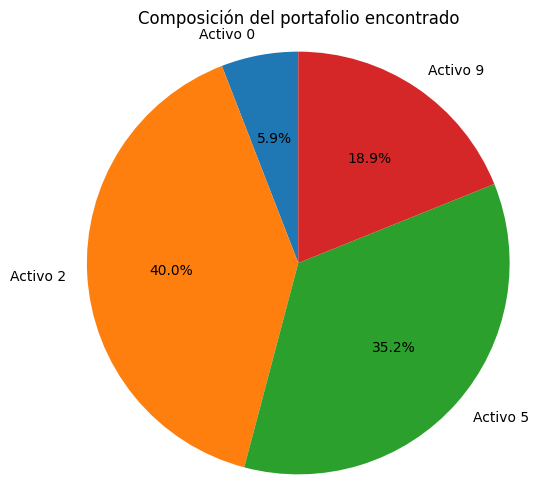


Métricas del Portafolio:
Retorno Esperado: 0.1409
Riesgo (Desviación Estándar): 0.1535
Ratio de Sharpe: 0.9180
Número de Activos: 4

Exposición por Sector:
Sector Consumo: 0.00%
Sector Tecnología: 41.10%
Sector Industrial: 18.90%
Sector Salud: 40.00%
Sector Finanzas: 0.00%


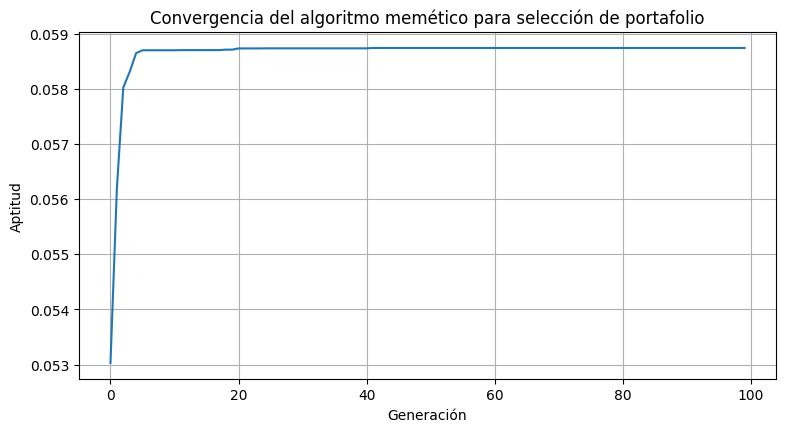

In [14]:
# Visualizar solución
algoritmo.visualizar_portafolio()

# Mostrar gráfica de convergencia
algoritmo.graficar_convergencia()

El portafolio encontrado tiene cuatro activos, uno menos que el máximo permitido, y son los cuatro de mayor retorno esperado. El activo 2, el de mayor retorno, queda en el límite del 40 %. La mejor aptitud sube rápido en las primeras generaciones y después de la generación 20 sus cambios son muy pequeños.

La aptitud que se imprime al final de la ejecución es algo menor que la mejor de las últimas generaciones. Como la búsqueda local final impone los límites $w_{\min} \le w_i \le w_{\max}$, la diferencia indica que la mejor solución de la evolución no los cumplía del todo, porque la reparación la había dejado por fuera de ellos al normalizar.

Como la reparación no garantiza la factibilidad, la celda siguiente revisa cada restricción en la mejor solución.

In [15]:
w = mejor_solucion['proporciones']
z = mejor_solucion['seleccion']
w_sel = w[z == 1]
print(f"Suma de proporciones: {w.sum():.6f}")
print(f"Activos seleccionados: {z.sum()} (máximo {algoritmo.max_activos})")
print(f"Proporción mínima entre los seleccionados: {w_sel.min():.4f} (límite {algoritmo.min_proporcion})")
print(f"Proporción máxima: {w_sel.max():.4f} (límite {algoritmo.max_proporcion})")
exposiciones = {s: sum(w[i] for i in range(n_activos) if sectores[i] == s) for s in sorted(set(sectores))}
print(f"Mayor exposición sectorial: {max(exposiciones.values()):.4f} (límite {algoritmo.max_sector})")

Suma de proporciones: 1.000000
Activos seleccionados: 4 (máximo 5)
Proporción mínima entre los seleccionados: 0.0589 (límite 0.05)
Proporción máxima: 0.4000 (límite 0.4)
Mayor exposición sectorial: 0.4110 (límite 0.5)


La solución final cumple todas las restricciones. La proporción máxima queda justo en el límite del 40 %, y la mayor exposición sectorial, la de tecnología, queda por debajo del 50 %.